In [70]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

In [71]:
df = pd.read_csv('../dane/przetworzone_dane/credit_risk_dataset_cleaned.csv', sep = ',')


df.head(10)

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,2,21,9600.0,OWN,5.0,EDUCATION,B,1000.0,11.14,0,0.10,N,2
1,3,25,9600.0,MORTGAGE,1.0,MEDICAL,C,5500.0,12.87,1,0.57,N,3
2,4,23,65500.0,RENT,4.0,MEDICAL,C,35000.0,15.23,1,0.53,N,2
3,5,24,54400.0,RENT,8.0,MEDICAL,C,35000.0,14.27,1,0.55,Y,4
4,6,21,9900.0,OWN,2.0,VENTURE,A,2500.0,7.14,1,0.25,N,2
5,7,26,77100.0,RENT,8.0,EDUCATION,B,35000.0,12.42,1,0.45,N,3
6,8,24,78956.0,RENT,5.0,MEDICAL,B,35000.0,11.11,1,0.44,N,4
7,9,24,83000.0,RENT,8.0,PERSONAL,A,35000.0,8.90,1,0.42,N,2
8,10,21,10000.0,OWN,6.0,VENTURE,D,1600.0,14.74,1,0.16,N,3
9,11,22,85000.0,RENT,6.0,VENTURE,B,35000.0,10.37,1,0.41,N,4


In [72]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32573 entries, 0 to 32572
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          32573 non-null  int64  
 1   person_age                  32573 non-null  int64  
 2   person_income               32573 non-null  float64
 3   person_home_ownership       32573 non-null  str    
 4   person_emp_length           32573 non-null  float64
 5   loan_intent                 32573 non-null  str    
 6   loan_grade                  32573 non-null  str    
 7   loan_amnt                   32573 non-null  float64
 8   loan_int_rate               32573 non-null  float64
 9   loan_status                 32573 non-null  int64  
 10  loan_percent_income         32573 non-null  float64
 11  cb_person_default_on_file   32573 non-null  str    
 12  cb_person_cred_hist_length  32573 non-null  int64  
dtypes: float64(5), int64(4), str(4)
memory usa

In [73]:
df.describe()

,id,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32573.000000,32573.000000,3.257300e+04,32573.000000,32573.000000,32573.000000,32573.000000,32573.000000,32573.000000
mean,16292.959015,27.716391,6.587977e+04,4.760691,9588.112854,11.013677,0.218187,0.170199,5.803457
std,9403.276188,6.194205,5.253223e+04,3.981188,6320.323455,3.212348,0.413021,0.106755,4.052234
min,2.000000,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,8150.000000,23.000000,3.850000e+04,2.000000,5000.000000,7.880000,0.000000,0.090000,3.000000
50%,16293.000000,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,24436.000000,30.000000,7.920000e+04,7.000000,12200.000000,13.480000,0.000000,0.230000,8.000000
max,32581.000000,84.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


# **1. Spłacalność kredytów.**

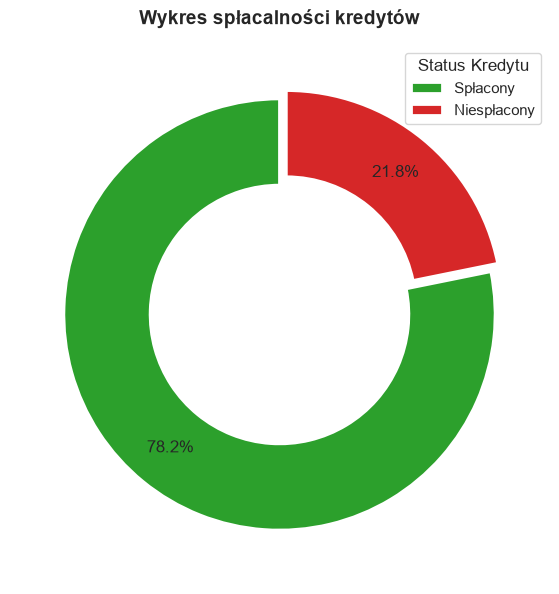

In [74]:
liczba = df['loan_status'].value_counts()

plt.figure(figsize=(9, 7))


liczba.plot.pie(
    autopct = '%1.1f%%', 
    startangle = 90, 
    colors = ['#2ca02c', '#d62728'],
    pctdistance = 0.80,
    explode = (0, 0.05),
    labels = None,
    wedgeprops = dict(width = 0.4, edgecolor = 'white', linewidth = 2)
)

plt.legend(
    title = 'Status Kredytu',
    labels = ['Spłacony', 'Niespłacony'],
    loc = 'upper right'
)

plt.title(
    'Wykres spłacalności kredytów',
    fontsize=14,
    pad=15,
    fontweight="bold",
)
plt.show()

### Wnioski do pkt. 1:
* Zbiór danych charakteryzuje się nierównowagą klas: 78,2% kredytobiorców spłaciło zobowiązanie (loan_status = 0), natomiast 21,8% nie spłaciło kredytu (loan_status = 1).

# **2. Rozkład wskażnika DTI (Dept To Income) w zależności od spłacalności.**

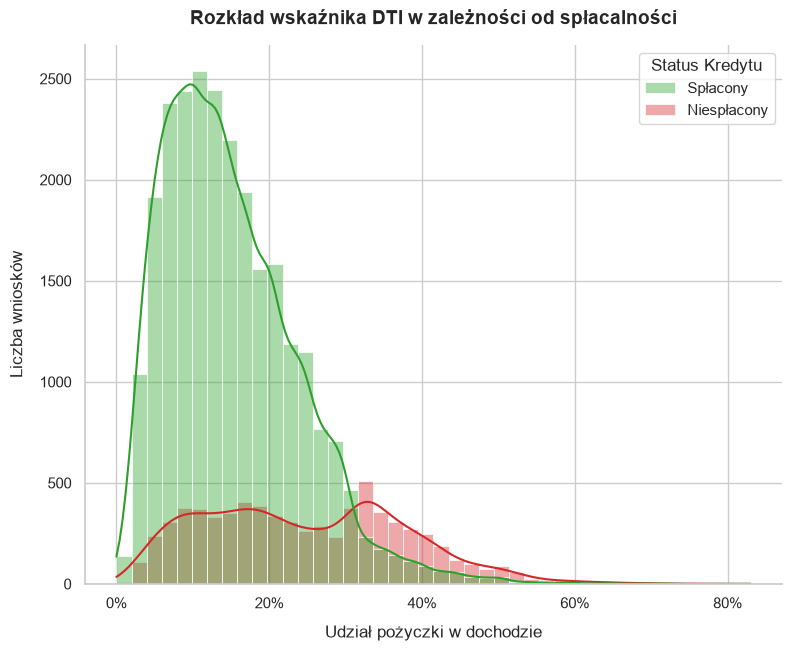

In [75]:
df['Status Kredytu'] = df['loan_status'].map({0: 'Spłacony', 1: 'Niespłacony'})

plt.figure(figsize = (9, 7))


sns.set_theme(style = "whitegrid")

ax = sns.histplot(
    data = df, 
    x = 'loan_percent_income', 
    hue = 'Status Kredytu', 
    kde = True,
    binwidth = 0.02,
    palette = ['#2ca02c', '#d62728'],
    alpha = 0.4,
    edgecolor = 'white',
    linewidth = 0.5
)

ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))

plt.title(
    "Rozkład wskaźnika DTI w zależności od spłacalności",
    fontsize=14,
    pad=15,
    fontweight="bold",
)
plt.xlabel("Udział pożyczki w dochodzie", fontsize=12, labelpad=10)
plt.ylabel("Liczba wniosków", fontsize=12, labelpad=10)

sns.despine()

plt.show()

### Wnioski do pkt. 2:
* Wyższe ryzyko przy wyższym obciążeniu dochodu: Osoby, które nie spłaciły kredytu, przeznaczały na niego średnio 24,7% swojego dochodu, w porównaniu do 14,9% w grupie spłacających.
* Przesunięcie rozkładów: Rozkład kredytów spłaconych wyraźnie skupia się wokół niskich wartości (poniżej 20% dochodu), podczas gdy rozkład dla kredytów niespłaconych jest przesunięty w stronę wyższych wartości i bardziej rozproszony.
* Wzrost odsetka niespłacalności: Wyraźny wzrost udziału kredytów niespłaconych widoczny jest po przekroczeniu progu 20-25% udziału pożyczki w dochodzie.

# **3. Rozkład oprocentowania pożyczki.**

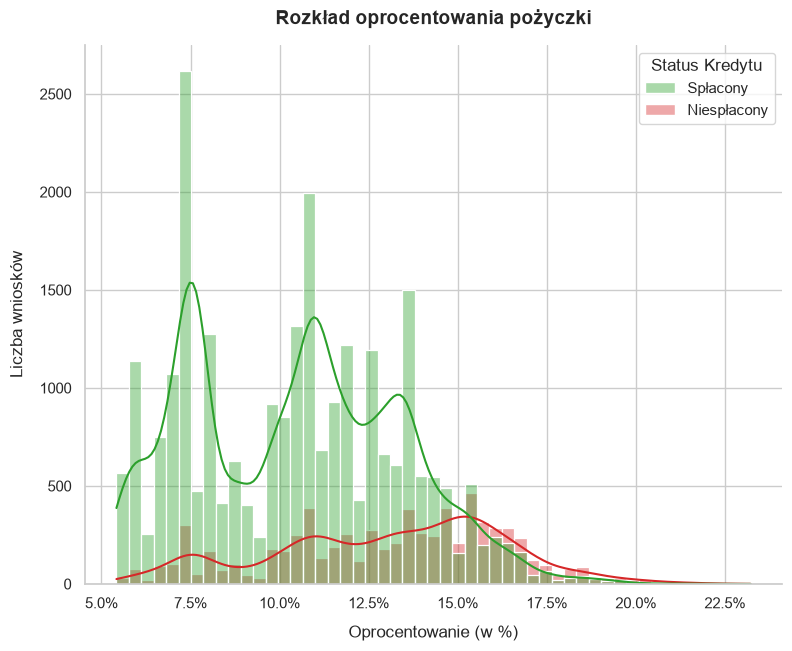

In [76]:
df['Status Kredytu'] = df['loan_status'].map({0: 'Spłacony', 1: 'Niespłacony'})

plt.figure(figsize=(9, 7))


sns.set_theme(style="whitegrid")

ax = sns.histplot(
    data = df, 
    x = 'loan_int_rate', 
    hue = 'Status Kredytu', 
    kde = True,
    palette = ['#2ca02c', '#d62728'],
    alpha = 0.4,
)

ax.xaxis.set_major_formatter(mtick.PercentFormatter(symbol = '%'))

plt.title(
    "Rozkład oprocentowania pożyczki",
    fontsize=14,
    pad=15,
    fontweight="bold",
)
plt.xlabel("Oprocentowanie (w %)", fontsize=12, labelpad=10)
plt.ylabel("Liczba wniosków", fontsize=12, labelpad=10)

sns.despine()

plt.show()

### Wnioski do pkt. 3:
* Wyższe oprocentowanie to wyższe ryzyko: Średnie oprocentowanie dla kredytów niespłaconych wynosi 13,0%, podczas gdy dla kredytów spłaconych wynosi 10%
* Przesunięcie rozkładu: Zdecydowana większość kredytów spłaconych koncentruje się w niższych przedziałach oprocentowania (poniżej 11%), natomiast rozkład kredytów niespłaconych jest przesunięty w stronę wyższych stóp procentowych.
* Próg wzrostu ryzyka: Wyraźny wzrost udziału kredytów niespłaconych widoczny jest po przekroczeniu poziomu 12-13% oprocentowania.

# **4. Wiek vs roczny dochód z podziałem na status spłaty kredytu.**

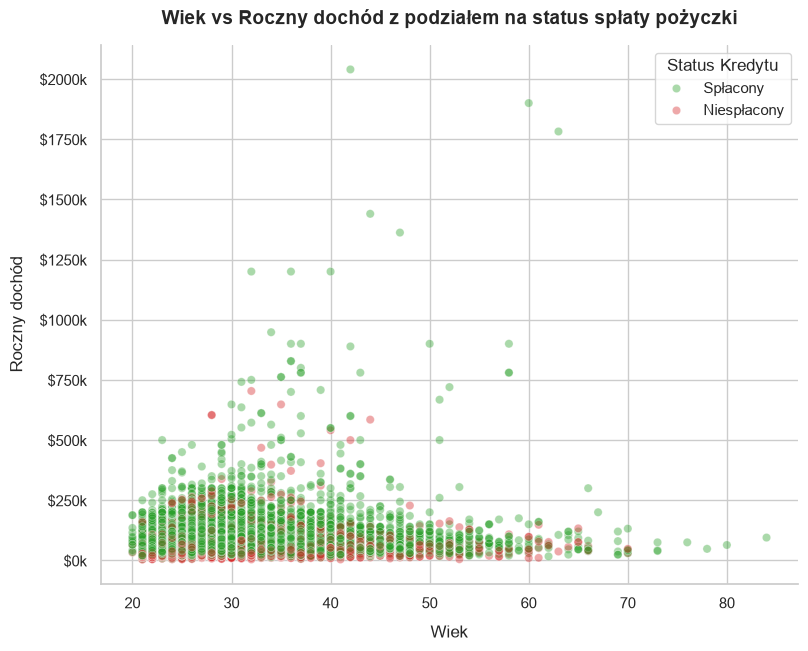

In [77]:
df['Status Kredytu'] = df['loan_status'].map({0: 'Spłacony', 1: 'Niespłacony'})

plt.figure(figsize=(9, 7))

sns.set_theme(style="whitegrid")

ax = sns.scatterplot(
    data = df,
    x = 'person_age',
    y = 'person_income',
    hue = 'Status Kredytu',
    palette = ['#2ca02c', '#d62728'],
    alpha = 0.4
)

ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda y, _: f'${int(y/1000)}k'))

plt.title(
    "Wiek vs Roczny dochód z podziałem na status spłaty pożyczki",
    fontsize=14,
    pad=15,
    fontweight="bold",
)

plt.xlabel("Wiek", fontsize=12, labelpad=10)
plt.ylabel("Roczny dochód", fontsize=12, labelpad=10)
plt.legend(title = "Status Kredytu")

sns.despine()

plt.show()

### Wnioski do pkt. 4:
* Silna zależność między dochodem a ryzykiem: W dolnej części wykresu (dochody poniżej 100 tys. USD) występuje bardzo wysokie zagęszczenie kredytów niespłaconych. Wynika z tego, że niski poziom dochodu jest głównym czynnikiem podwyższającym ryzyko niewypłacalności.
* Ochronny wpływ wysokich zarobków: Powyżej poziomu 200-250 tys. USD dochodu pojawiają się niemal wyłącznie kredyty spłacone. Z wysokiego dochodu wynika wysoka zdolność finansowa do regulowania zobowiązań, co czyni z tej zmiennej bardzo silny predyktor spłacalności.
* Brak wpływu wieku na spłacalność: Zarówno kredyty spłacone, jak i niespłacone są równomiernie rozłożone w całym przedziale wiekowym (20-60+ lat). Wynika z tego, że sam wiek klienta nie niesie ze sobą wartości predykcyjnej dla ryzyka kredytowego.

# 5. **Wskaźnik niewypłacalności w podziale na grupy wiekowe.**

C:\Users\User\AppData\Local\Temp\ipykernel_7596\801097397.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


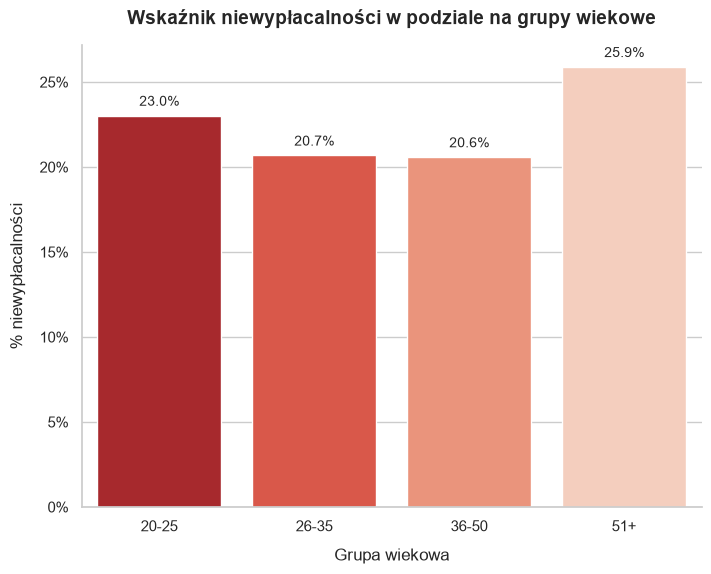

In [78]:
bins = [18, 25, 35, 50, 100]
labels = ['20-25', '26-35', '36-50', '51+']

df['Grupa wiekowa'] = pd.cut(df['person_age'], bins = bins, labels = labels, right = True)

niewyplacalnosc = df.groupby('Grupa wiekowa')['loan_status'].mean().reset_index()


plt.figure(figsize=(8, 6))

sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data = niewyplacalnosc,
    x = 'Grupa wiekowa',
    y = 'loan_status',
    palette = 'Reds_r',
    dodge = False,
    legend = False
)

ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals = 0))

plt.title("Wskaźnik niewypłacalności w podziale na grupy wiekowe",
    fontsize=14,
    pad=15,
    fontweight="bold",
)

for container in ax.containers:
    values = container.datavalues
    labels = [f'{v * 100:.1f}%' for v in values]
    ax.bar_label(container, labels = labels, fontsize = 10, padding = 5)

plt.xlabel("Grupa wiekowa", fontsize=12, labelpad=10)
plt.ylabel("% niewypłacalności", fontsize=12, labelpad=10)

sns.despine()

plt.show()

### Wnioski do pkt. 5:
* Niewielkie różnice między grupami: Wskaźnik niewypłacalności we wszystkich grupach wiekowych kształtuje się na zbliżonym poziomie – od 20,5% do 25,9%.
* Najwyższa niewypłacalność: Najwyższy odsetek braku spłaty występuje w grupie 51+ (25,9%) oraz wśród najmłodszych kredytobiorców w wieku 20–25 lat (23,0%).
* Najniższa niewypłacalność: Grupy wiekowe 26–35 lat (20,7%) oraz 36–50 lat (20,6%) wykazują najniższy i niemal identyczny poziom ryzyka.
* Nierównomierny rozkład próby: Blisko 90% wszystkich kredytobiorców stanowią osoby do 35. roku życia, podczas gdy grupa 51+ liczy jedynie 282 osoby, co oznacza, że wyższy wskaźnik w najstarszej grupie opiera się na znacznie mniejszej liczbie obserwacji.

# 6. **Wskaźnik niewypłacalności w podziale na cel kredytu.**

C:\Users\User\AppData\Local\Temp\ipykernel_7596\3310829425.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


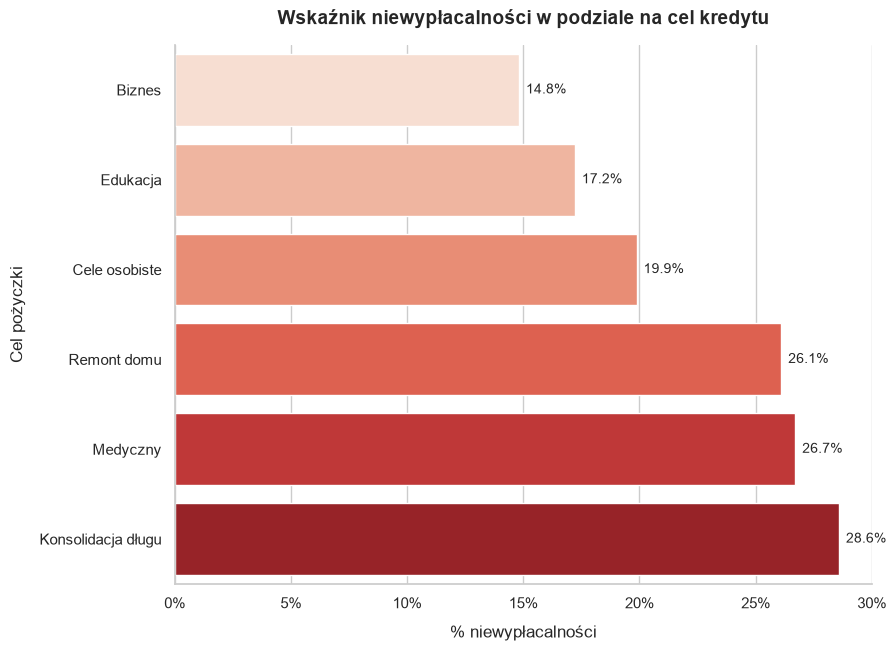

In [79]:
plt.figure(figsize=(9, 7))

sns.set_theme(style="whitegrid")

Cel_pozyczki = df.groupby('loan_intent')['loan_status'].mean().reset_index()
Cel_pozyczki['Cel pozyczki'] = Cel_pozyczki['loan_intent'].map({
    'EDUCATION': 'Edukacja',
    'MEDICAL': 'Medyczny',
    'VENTURE': 'Biznes',
    'PERSONAL': 'Cele osobiste',
    'HOMEIMPROVEMENT': 'Remont domu',
    'DEBTCONSOLIDATION': 'Konsolidacja długu'
})

Cel_pozyczki = Cel_pozyczki.sort_values(by = 'loan_status')

ax = sns.barplot(
    data = Cel_pozyczki,
    x = 'loan_status',
    y = 'Cel pozyczki',
    palette = 'Reds',
    legend = False
)

ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals = 0))

plt.title("Wskaźnik niewypłacalności w podziale na cel kredytu",
    fontsize=14,
    pad=15,
    fontweight="bold",
)

for container in ax.containers:
    values = container.datavalues
    labels = [f'{v * 100:.1f}%' for v in values]
    ax.bar_label(container, labels = labels, fontsize = 10, padding = 5)

plt.xlabel("% niewypłacalności", fontsize=12, labelpad=10)
plt.ylabel("Cel pożyczki", fontsize=12, labelpad=10)

sns.despine()

plt.show()

### Wnioski do pkt. 6:
* Najbardziej ryzykowne cele pożyczki: Najwyższy odsetek braku spłaty wykazują Konsolidacja długu (28,6%), cele Medyczne (26,7%) oraz Remont domu (26,1%).
* Najbezpieczniejsze cele pożyczki: Najniższym ryzykiem charakteryzują się pożyczki na Biznes (14,8%) oraz Edukację (17,2%).
* Dwukrotna różnica w ryzyku: Ryzyko niewypłacalności przy konsolidacji długu jest prawie dwukrotnie wyższe niż w przypadku pożyczek na cele biznesowe.
* Charakter wydatku a spłacalność: Kredyty zaciągane na pokrycie istniejącego zadłużenia lub nieplanowanych wydatków losowych (medycznych) są obarczone znacznie większym ryzykiem niż kredyty o charakterze inwestycyjnym (rozwój firmy, edukacja).

# 7. **Wskaźnik niewypłacalności w podziale na ocene kredytu.**

C:\Users\User\AppData\Local\Temp\ipykernel_7596\1670486783.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


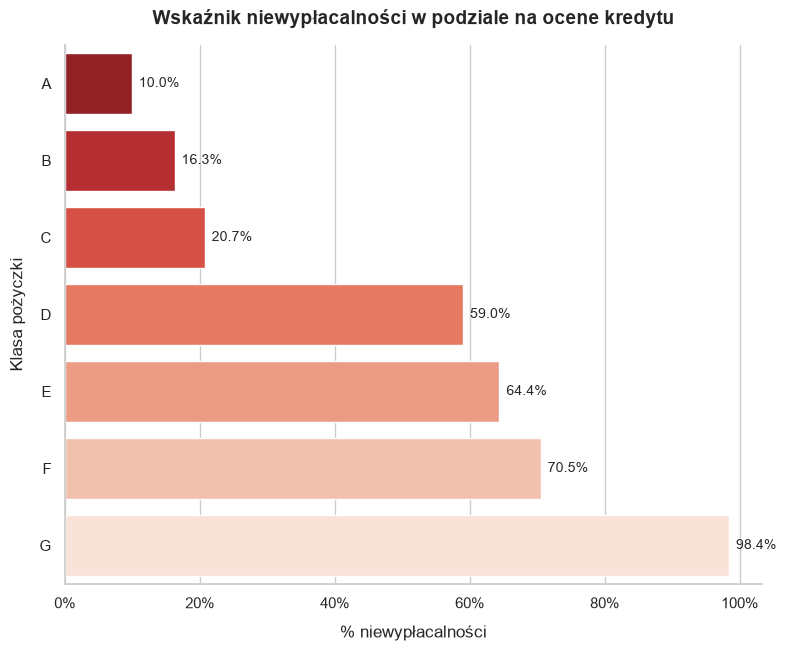

In [80]:
plt.figure(figsize=(9, 7))

sns.set_theme(style="whitegrid")

Klasa_pozyczki = df.groupby('loan_grade')['loan_status'].mean().reset_index()

Klasa_pozyczki = Klasa_pozyczki.sort_values(by = 'loan_status')

ax = sns.barplot(
    data = Klasa_pozyczki,
    x = 'loan_status',
    y = 'loan_grade',
    palette = 'Reds_r',
    legend = False
)

ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))

plt.title("Wskaźnik niewypłacalności w podziale na ocene kredytu",
    fontsize=14,
    pad=15,
    fontweight="bold",
)

for container in ax.containers:
    values = container.datavalues
    labels = [f'{v * 100:.1f}%' for v in values]
    ax.bar_label(container, labels = labels, fontsize = 10, padding = 5)

plt.xlabel("% niewypłacalności", fontsize=12, labelpad=10)
plt.ylabel("Klasa pożyczki", fontsize=12, labelpad=10)

sns.despine()

plt.show()

### Wnioski do pkt. 7:
* Idealna spójność oceny ryzyka: Wskaźnik niewypłacalności rośnie bezpośrednio wraz ze spadkiem klasy kredytowej - od 10,0% dla klasy A do 98,4% dla klasy G.
* Gwałtowny skok ryzyka od klasy D: Największy wzrost niewypłacalności następuje między klasami C (20,7%) a D (59,0%) - pożyczki od klasy D wykazują ponad 50% ryzyka braku spłaty.
* Skrajne ryzyko najniższych klas: Kredyty z klas E, F oraz G charakteryzują się większym prawdopodobieństwem braku spłaty niż terminowej regulacji (odpowiednio 64,4%, 70,5% i 98,4%).
* Wysoka skuteczność scoringu: Przyznawane klasy ratingowe bardzo trafnie odzwierciedlają rzeczywiste ryzyko kredytowe klienta.

# **8. Rozkład statusu spłaty kredytu według formy własności.**

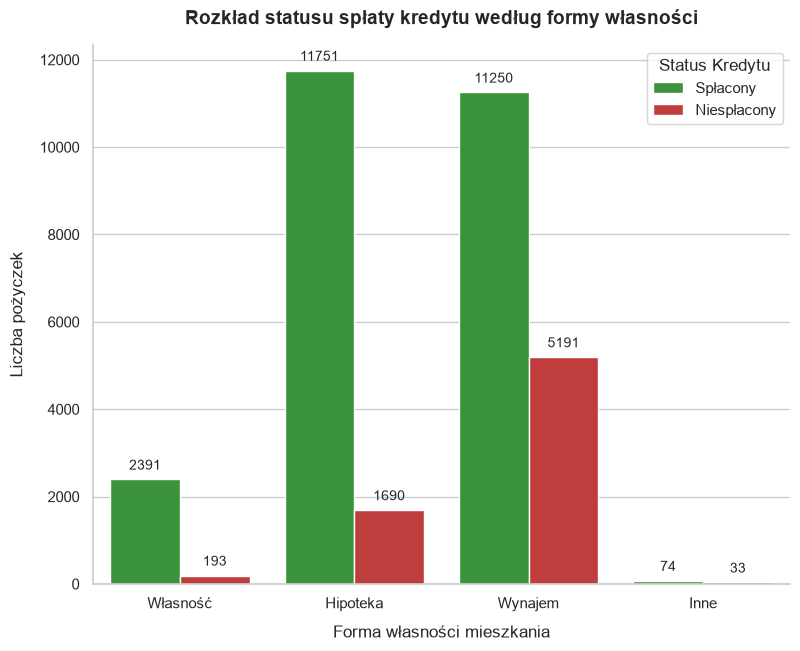

In [81]:
df['Status Kredytu'] = df['loan_status'].map({0: 'Spłacony', 1: 'Niespłacony'})

df['Forma Wlasnosci'] = df['person_home_ownership'].map({'OWN': 'Własność', 'MORTGAGE': 'Hipoteka',
                                                         'RENT': 'Wynajem', 'OTHER': 'Inne'})

plt.figure(figsize=(9, 7))

sns.set_theme(style="whitegrid")

ax = sns.countplot(
    data = df,
    x = 'Forma Wlasnosci',
    hue = 'Status Kredytu',
    palette = ['#2ca02c', '#d62728']
)

for container in ax.containers:
    ax.bar_label(container, fontsize = 10, padding = 5)

plt.title('Rozkład statusu spłaty kredytu według formy własności',
    fontsize=14,
    pad=15,
    fontweight="bold"
)

plt.xlabel('Forma własności mieszkania', fontsize=12, labelpad=10)
plt.ylabel('Liczba pożyczek', fontsize=12, labelpad=10)

sns.despine()

plt.show()

### Wnioski do pkt. 8:
* Dominacja wynajmujących i posiadaczy hipoteki: Zdecydowana większość kredytów przypada na osoby wynajmujące mieszkanie (16 441) oraz posiadające nieruchomość obciążoną hipoteką (13 441). Osoby z własnym mieszkaniem stanowią niewielki odsetek próby (2 584).
* Najwyższe ryzyko wśród osób wynajmujących: W grupie wynajmujących odnotowano zdecydowanie najwięcej niespłaconych pożyczek (5 191 przypadków), co przekłada się na wskaźnik niewypłacalności wynoszący 31,6% (prawie 1 na 3 kredyty).
* Wysoka spłacalność przy własności nieruchomości: Kredytobiorcy posiadający własne mieszkanie charakteryzują się najniższym wskaźnikiem braku spłaty (7,5% / 193 przypadki). Dla osób z hipoteką wskaźnik ten wynosi 12,6% (1 690 przypadków).
* Wpływ stabilności majątkowej na ryzyko: Posiadanie majątku trwałego (własność lub hipoteka) wiąże się ze znacznie wyższą dyscypliną płatniczą i niższym ryzykiem kredytowym niż wynajem lokalu.

# **9. Wpływ wcześniejeszego bankructwa na obecną spłatę.**

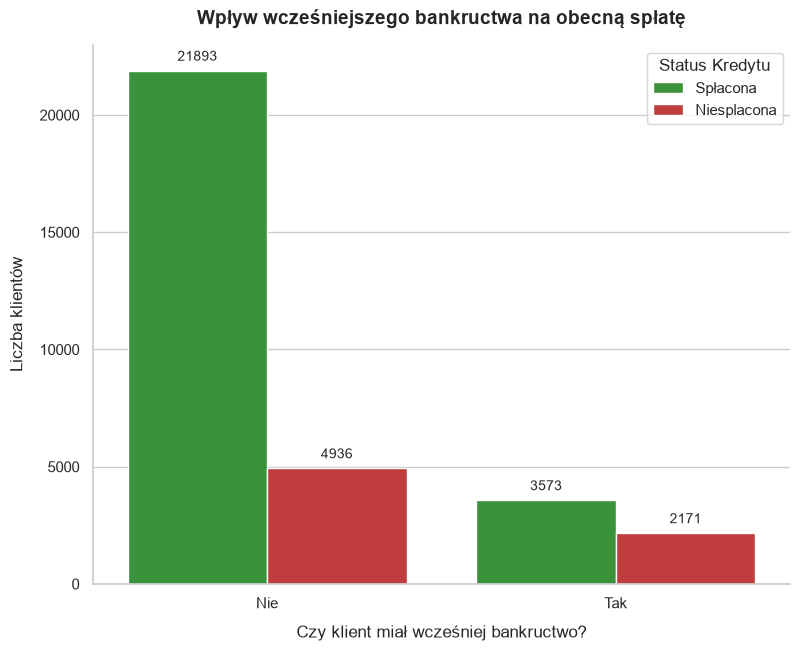

In [82]:
df['Status Kredytu'] = df['loan_status'].map({0: 'Spłacona', 1: 'Niesplacona'})

df['Czy zbankrutował'] = df['cb_person_default_on_file'].map({'Y': 'Tak', 'N': 'Nie'})

plt.figure(figsize=(9, 7))

sns.set_theme(style="whitegrid")

ax = sns.countplot(
    data = df, 
    x = 'Czy zbankrutował', 
    hue = 'Status Kredytu', 
    palette = ['#2ca02c', '#d62728']
)

for container in ax.containers:
    ax.bar_label(container, fontsize = 10, padding = 5)

plt.title('Wpływ wcześniejszego bankructwa na obecną spłatę', 
    fontsize = 14,
    pad = 15,
    fontweight = "bold"
)

plt.xlabel('Czy klient miał wcześniej bankructwo?', fontsize = 12, labelpad = 10)
plt.ylabel('Liczba klientów', fontsize = 12, labelpad = 10)

sns.despine()

plt.show()

### Wnioski do pkt. 9:
* Dwukrotnie wyższe ryzyko: Wśród klientów z historią niewypłacalności („Tak”) odsetek niespłaconych pożyczek wynosi 37,8% (2 171 osób), w porównaniu do 18,4% (4 936 osób) w grupie bez złej historii („Nie”).
* Znacząca różnica w spłacalności: Osoby bez historii bankructwa spłacają pożyczki w 81,6% przypadków, podczas gdy w grupie z historią wskaźnik ten spada do 62,2%.
* Struktura próby: Zdecydowana większość klientów w bazie (26 829 osób, tj. 82,4%) nie posiada wcześniejszych wpisów o niewypłacalności.
* Silny wskaźnik ryzyka: Wcześniejsze problemy ze spłatą zobowiązań stanowią jeden z najbardziej jednoznacznych predyktorów ponownego braku spłaty pożyczki.

# **10. Macierz korelacji.**

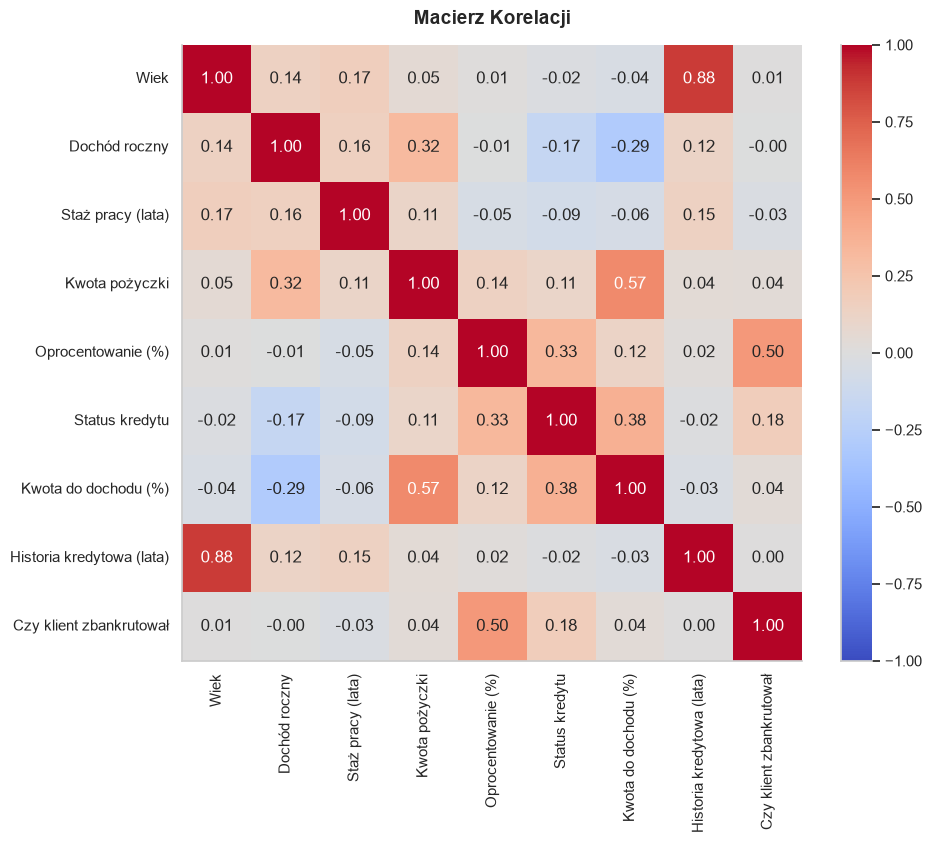

In [83]:
df['Czy klient zbankrutował'] = df['cb_person_default_on_file'].map({'Y': 1, 'N': 0})

nowe_nazwy = {
    'person_age': 'Wiek',
    'person_income': 'Dochód roczny',
    'person_emp_length': 'Staż pracy (lata)',
    'loan_amnt': 'Kwota pożyczki',
    'loan_int_rate': 'Oprocentowanie (%)',
    'loan_status': 'Status kredytu',
    'loan_percent_income': 'Kwota do dochodu (%)',
    'cb_person_cred_hist_length': 'Historia kredytowa (lata)',
}

corr_matrix = df.drop(columns=['id']).corr(method = 'pearson', numeric_only = True)

corr_matrix = corr_matrix.rename(columns = nowe_nazwy, index = nowe_nazwy)


plt.figure(figsize=(10, 8))

sns.set_theme(style="whitegrid")

sns.heatmap(
    corr_matrix,
    annot = True,
    fmt = ".2f",
    cmap = 'coolwarm',
    vmin = -1,
    vmax = 1
)

plt.title('Macierz Korelacji',     
    fontsize = 14,
    pad = 15,
    fontweight = "bold"
)

sns.despine()

plt.show()

### Wnioski do pkt. 10:
* Najsilniejsze predyktory niewypłacalności (Status kredytu):
    * Kwota do dochodu (%) ($r = 0,38$): Najsilniejsza dodatnia korelacja - im wyższy udział pożyczki w dochodzie, tym wyższe ryzyko braku spłaty.
    * Oprocentowanie (%) ($r = 0,33$): Wyższe oprocentowanie wiąże się ze wzrostem ryzyka niewypłacalności.
    * Dochód roczny ($r = -0,17$): Ujemna korelacja – wyższy dochód sprzyja prawidłowej spłacie kredytu.
* Silne zależności między zmiennymi (Multikolinearność):
    * Wiek a Historia kredytowa ($r = 0,88$): Bardzo silna korelacja liniowa - starsi klienci naturalnie posiadają dłuższą historię kredytową.
    * Kwota pożyczki a Kwota do dochodu (%) ($r = 0,57$): Wyższa kwota pożyczki bezpośrednio podnosi wskaźnik obciążenia dochodu.
    * Oprocentowanie a Wcześniejsze bankructwo ($r = 0,50$): Klienci z historią bankructwa otrzymują wyżej oprocentowane pożyczki.
* Brak liniowej zależności ze spłacalnością:
    * Wiek ($r = -0,02$) oraz Historia kredytowa ($r = -0,02$) nie wykazują niemal żadnej bezpośredniej korelacji liniowej ze statusem spłaty kredytu.

# **11. Zależność między wiekiem a długościa historii kredytowej (Korelacja: 0.88).**

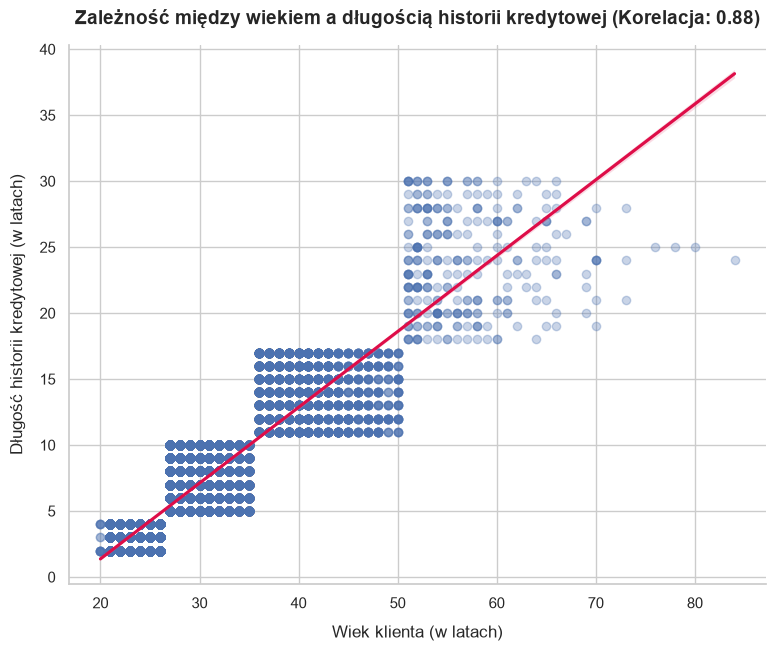

In [84]:
plt.figure(figsize=(9, 7))

sns.set_theme(style="whitegrid")

sns.regplot(
    x = 'person_age', 
    y = 'cb_person_cred_hist_length', 
    data = df, 
    line_kws = {'color': "#de0d48"},
    scatter_kws = {'alpha': 0.3}
)

plt.title('Zależność między wiekiem a długością historii kredytowej (Korelacja: 0.88)',
    fontsize = 14,
    pad = 15,
    fontweight = "bold"
)

plt.xlabel('Wiek klienta (w latach)', fontsize = 12, labelpad = 10)
plt.ylabel('Długość historii kredytowej (w latach)', fontsize = 12, labelpad = 10)

sns.despine()

plt.show()

### Wnioski do pkt. 11:
* Bardzo silna zależność liniowa ($r = 0,88$): Długość historii kredytowej jest bezpośrednio powiązana z wiekiem klienta - starsze osoby posiadają proporcjonalnie dłuższą historię kredytową.
* Stałe tempo przyrostu: Linia regresji pokazuje stabilny wzrost historii kredytowej o około 0,57 roku na każdy kolejny rok życia klienta.
* Zjawisko multikolinearności: Prawie doskonała korelacja oznacza, że wiek oraz długość historii kredytowej przenoszą w zbiorze danych niemal identyczną informację.
* Naturalny wiek startowy: Rozkład punktów wynika z faktu, że klienci rozpoczynają budowanie historii kredytowej najwcześniej po osiągnięciu pełnoletniości (ok. 18-20. roku życia).